# How much of the SWE-bench Verified leaderboard is luck?

- This notebook uses the public per-task results of every SWE-bench Verified
  submission to check which gaps on the leaderboard are real
  - The data is pinned to commit `40f164d` of `SWE-bench/experiments`
  - The numbers in the text are for that snapshot
- The pedagogical arc:
  - The benchmark, the submissions, and a check of the data
  - How uncertain each score is
  - Whether the leaderboard can tell neighbors apart
  - How many tasks it would take to resolve the gaps it shows

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import pandas as pd

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpa7qqwf6w.json --HistoryManager.hist_file=:memory:


# Part 1: The benchmark and the submissions

## Cell 1.1: Load the data

- SWE-bench Verified has 500 real GitHub issues from 12 Python repos
  - A fix counts only if it passes the tests of the issue
- Every submission publishes which tasks it solved
  - So the whole leaderboard becomes a 0/1 matrix of agents x tasks

In [3]:
# Load the outcome matrix and the metadata saved by `fetch_swebench_verified.py`.
outcomes, submissions, tasks = utils.load_swebench_dataset("data")

print("outcomes.shape=", outcomes.shape)
print("len(submissions)=", len(submissions))
# Outcome: 173 usable submissions out of 182, all on the same 500 tasks.

outcomes.shape= (173, 500)
len(submissions)= 182


In [4]:
# Show the submissions left out of the analysis, and why.
excluded = submissions.loc[
    submissions["excluded_reason"] != "", ["name", "excluded_reason"]
]

display(excluded)
# Outcome: 7 submissions have no per-task results, and 2 have per-task results
# that do not match their own reported score.

,name,excluded_reason
submission,,
20250720_mini-v0.0.0-Llama-4-Scout-17B-Instruct,Llama 4 Scout Instruct,no per-task results
20250720_mini-v0.0.0-claude-3-7-sonnet-20250219,Claude 3.7 Sonnet (20250219),per-task score 10.2% disagrees with the report...
20250720_mini-v0.0.0-gpt-4o-2024-11-20,GPT 4o (2024-11-20),no per-task results
20250720_mini-v0.0.0_gpt-4.1-mini-2025-04-14,GPT 4.1 mini (2025-04-14),no per-task results
20250726_mini-v1.0.0_gemini-2.0-flash,Gemini 2.0 Flash,no per-task results
20250726_mini-v1.0.0_gemini-2.5-flash,Gemini 2.5 Flash (2025-04-17),no per-task results
20250726_mini-v1.0.0_gpt-4.1-2025-04-14,GPT 4.1 (2025-04-14),no per-task results
20260219_mini-v2.0.0_gpt-5-2-codex,GPT 5.2 Codex,no per-task results
20260226_mini-v2.0.0_gemini-3-pro-high,Gemini 3 Pro,per-task score 0.0% disagrees with the reporte...


## Cell 1.2: Check the data against the reported scores

- If the parsing is right, the score computed from the per-task results should
  match the score each submission reports

In [5]:
# Compare the recomputed scores with the reported ones, in points.
kept = submissions.loc[outcomes.index]
mismatch = (kept["score"] - kept["reported_score"]).abs()

print("mismatch.count()=", mismatch.count())
print("mismatch.max()=", round(mismatch.max(), 2), "points")
# Outcome: all 39 submissions that report a score are within 0.13 points of it.

mismatch.count()= 39
mismatch.max()= 0.13 points


## Cell 1.3: The leaderboard

In [6]:
# Rank the agents by the share of tasks solved, like the official site.
leaderboard = utils.compute_leaderboard(outcomes, submissions)

display(
    leaderboard.head(10)[["rank", "label", "score", "n_resolved", "attempts"]]
)
# Outcome: the top 10 are within 3.4 points of each other.

,rank,label,score,n_resolved,attempts
submission,,,,,
20251205_sonar-foundation-agent_claude-opus-4-5,1,Sonar Foundation Agent + Claude 4.5 Opus,0.792,396,1
20251215_livesweagent_claude-opus-4-5,1,live-SWE-agent + Claude 4.5 Opus medium (20251...,0.792,396,1
20250928_trae_doubao_seed_code,3,TRAE + Doubao-Seed-Code,0.788,394,2+
20251127_openhands_claude-opus-4-5,4,OpenHands + Claude Opus 4.5,0.776,388,
20251120_livesweagent_gemini-3-pro-preview,5,live-SWE-agent + Gemini 3 Pro Preview (2025-11...,0.774,387,1
20250804_epam-ai-run-claude-4-sonnet,6,EPAM AI/Run Developer Agent v20250719 + Claude...,0.768,384,2+
20250902_atlassian-rovo-dev,6,Atlassian Rovo Dev (2025-09-02),0.768,384,2
20260217_mini-v2.0.0_claude-4-5-opus-high,6,Claude 4.5 Opus (high),0.768,384,1
20250819_ACoder,9,ACoder,0.764,382,2+


## Cell 1.4: Attempts allowed per task

- Some submissions try several times per task and submit the best attempt
  - This is a selection effect, which Milestone 4 looks at

In [7]:
# Count the submissions by the number of attempts they allow per task.
attempts = leaderboard["attempts"].replace("", "not reported").value_counts()

display(attempts)
# Outcome: about half of the submissions allow more than 1 attempt.

attempts
1               83
2+              81
not reported     8
2                1
Name: count, dtype: int64

In [8]:
# Compare the 2 EntroPO submissions: the same system with 1 and with several
# attempts.
entropo = leaderboard[leaderboard["name"].str.startswith("EntroPO")]

display(entropo[["label", "score", "attempts"]])
# Outcome: allowing several attempts adds about 8 points.

,label,score,attempts
submission,,,
20250901_entroPO_R2E_QwenCoder30BA3B_tts,EntroPO + R2E + Qwen3-Coder-30B-A3B-Instruct (...,0.604,2+
20250901_entroPO_R2E_QwenCoder30BA3B,EntroPO + R2E + Qwen3-Coder-30B-A3B-Instruct (...,0.522,1


# Part 2: The uncertainty of each score

## Cell 2.1: Interval on every score

- The 500 tasks are 1 sample from a bigger pool of similar issues
- A bootstrap over tasks shows how much each score would move with a different
  sample of 500

In [9]:
# Compute a 95% interval for every score.
cis = utils.compute_score_cis(outcomes)
width = 100 * (cis["ci_high"] - cis["ci_low"])

print("width.median()=", round(width.median(), 1), "points")
# Outcome: a typical score is only known to within about +/- 4 points.

width.median()= 8.2 points


## Cell 2.2: The top of the leaderboard with its intervals

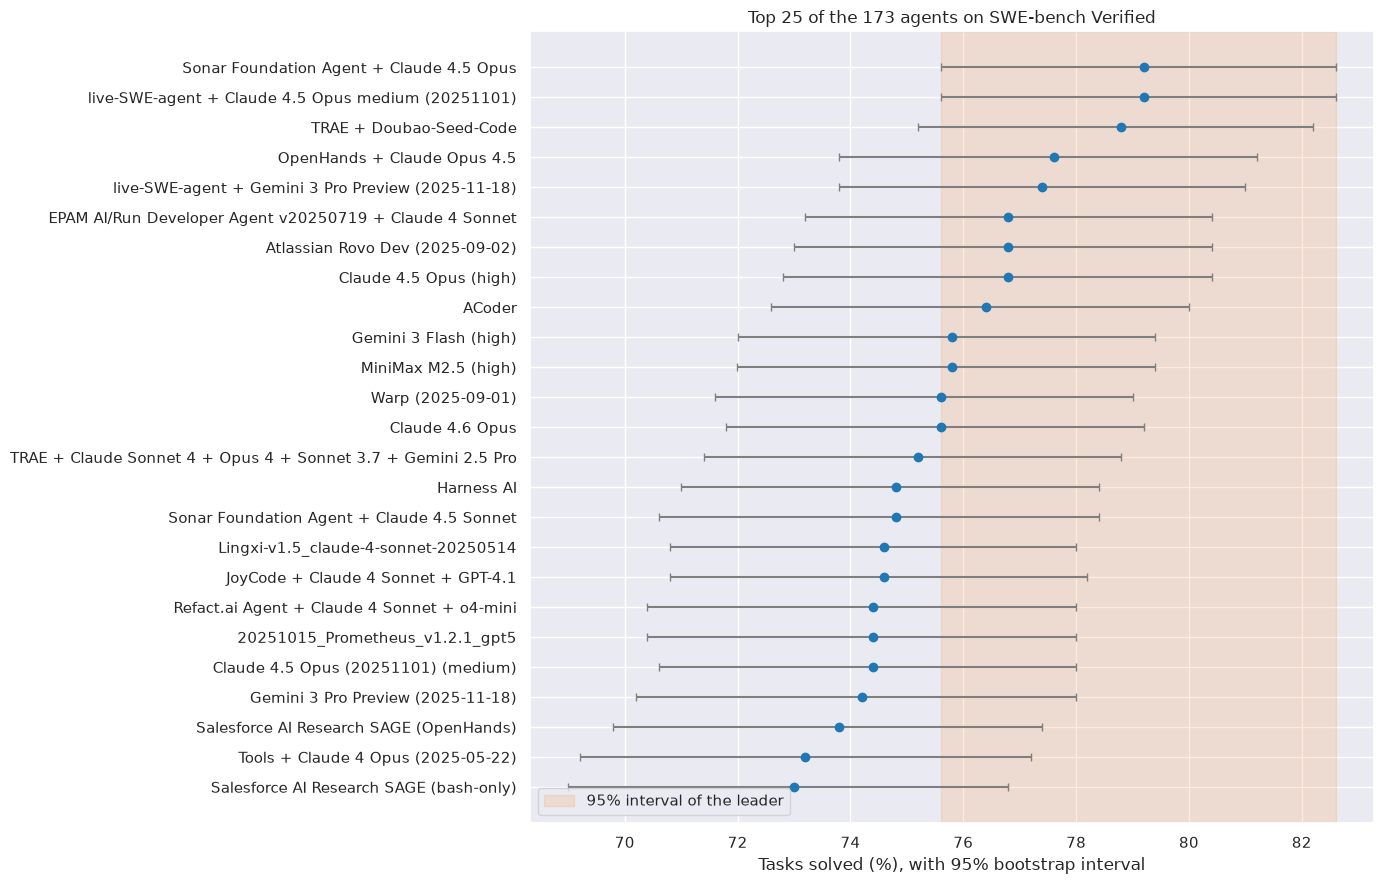

In [10]:
# Plot the top 25 agents, shading the interval of the leader.
utils.plot_leaderboard_cis(leaderboard, cis, top_k=25, figsize=(14, 9))

# Part 3: Can the leaderboard tell neighbors apart?

## Cell 3.1: Test every pair of neighbors

- Each agent is compared with the next one down, task by task
  - A paired bootstrap gives an interval for the gap
  - The exact McNemar test gives a p-value
- With 172 pairs, the Holm adjustment keeps the chance of any false positive
  at 5%

In [11]:
# Compare every agent with the next one on the leaderboard.
adjacent = utils.compare_adjacent_ranks(outcomes, leaderboard)
# Count the pairs that differ before and after the Holm adjustment.
median_gap = 100 * adjacent["gap"].abs().median()
num_raw_significant = int((adjacent["p_value"] < 0.05).sum())
num_distinguishable = int(adjacent["distinguishable"].sum())

print("len(adjacent)=", len(adjacent))
print("median_gap=", round(median_gap, 1), "points")
print("num_raw_significant=", num_raw_significant)
print("num_distinguishable=", num_distinguishable)
# Outcome: the typical gap between neighbors is 0.2 points, and no pair can be
# told apart after Holm.

len(adjacent)= 172
median_gap= 0.2 points
num_raw_significant= 2
num_distinguishable= 0


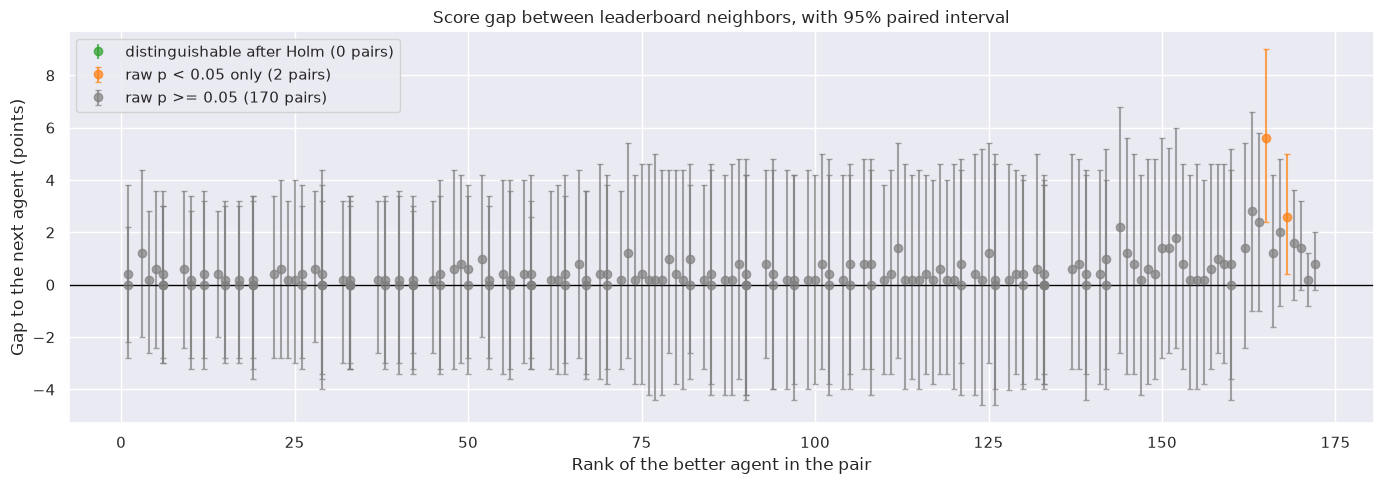

In [12]:
# Plot the gap between each pair of neighbors, with its paired interval.
utils.plot_adjacent_gaps(adjacent, figsize=(14, 5))

## Cell 3.2: Who is tied with the leader?

- Which agents can the data not separate from the agent ranked first?
- The decision uses the Holm-adjusted p-value, since there are 172
  comparisons with the leader
  - The intervals in the table are not adjusted, so 10 of the 18 exclude 0 even
    though those agents are tied after the adjustment
- The leader was picked for having the top observed score, which makes its
  lead look bigger than it is (winner's curse)
  - So, if anything, this undercounts the ties

In [13]:
# Compare every agent with the leader.
versus_leader = utils.compare_to_leader(outcomes, leaderboard)
tied = versus_leader[versus_leader["tied_with_leader"]]
leader = leaderboard["label"].iloc[0]

print("leader=", leader)
print("len(tied)=", len(tied))
# Show the agents tied with the leader.
columns = ["rank", "label", "gap", "ci_low", "ci_high", "p_holm"]
display(tied[columns].round(4).reset_index(drop=True))
# Outcome: 18 agents, down to rank 19, are statistically tied for first place.

leader= Sonar Foundation Agent + Claude 4.5 Opus
len(tied)= 18


,rank,label,gap,ci_low,ci_high,p_holm
0,1,live-SWE-agent + Claude 4.5 Opus medium (20251...,0.000,-0.022,0.022,1.0000
1,3,TRAE + Doubao-Seed-Code,0.004,-0.026,0.036,1.0000
2,4,OpenHands + Claude Opus 4.5,0.016,-0.006,0.040,0.9719
3,5,live-SWE-agent + Gemini 3 Pro Preview (2025-11...,0.018,-0.010,0.044,0.9719
4,6,EPAM AI/Run Developer Agent v20250719 + Claude...,0.024,-0.006,0.054,0.8020
5,6,Atlassian Rovo Dev (2025-09-02),0.024,-0.004,0.052,0.8020
6,6,Claude 4.5 Opus (high),0.024,0.000,0.050,0.7691
7,9,ACoder,0.028,-0.002,0.060,0.7998
8,10,Gemini 3 Flash (high),0.034,0.004,0.064,0.3962
9,10,MiniMax M2.5 (high),0.034,0.004,0.066,0.3962


# Part 4: How many tasks would it take?

## Cell 4.1: Tasks needed for a given gap

- $\sigma_d$, the std of the per-task difference between 2 neighbors, sets how
  fast the paired gap estimate gets sharper with more tasks
- With the median $\sigma_d$ of the neighbor pairs, we get the number of tasks
  needed to resolve a gap at 80% power

In [14]:
# Compute the tasks needed for a few gap sizes, with the median `sd_diff`.
sd_diff = adjacent["sd_diff"].median()
gaps = [0.01, 0.02, 0.03, 0.05]
min_tasks = pd.Series(
    [utils.compute_min_tasks(sd_diff, gap) for gap in gaps],
    index=[f"{100 * gap:.0f} points" for gap in gaps],
    name="tasks needed",
)

print("sd_diff=", round(sd_diff, 3))
display(min_tasks.round(0))
# Outcome: a 1-point gap needs about 14,700 tasks, almost 30 times the size of
# the benchmark.

sd_diff= 0.433


1 points    14707.0
2 points     3677.0
3 points     1634.0
5 points      588.0
Name: tasks needed, dtype: float64

## Cell 4.2: The smallest gap 500 tasks can resolve

- Solving the same formula for the gap gives the smallest gap that 500 tasks
  detect with 80% power

In [15]:
# Compute the smallest resolvable gap for the real benchmark size.
min_gap = utils.compute_min_detectable_gap(sd_diff, outcomes.shape[1])

print("min_gap=", round(100 * min_gap, 1), "points")
# Outcome: 500 tasks resolve gaps of about 5.4 points or more, while the
# typical gap between neighbors is 0.2 points.

min_gap= 5.4 points


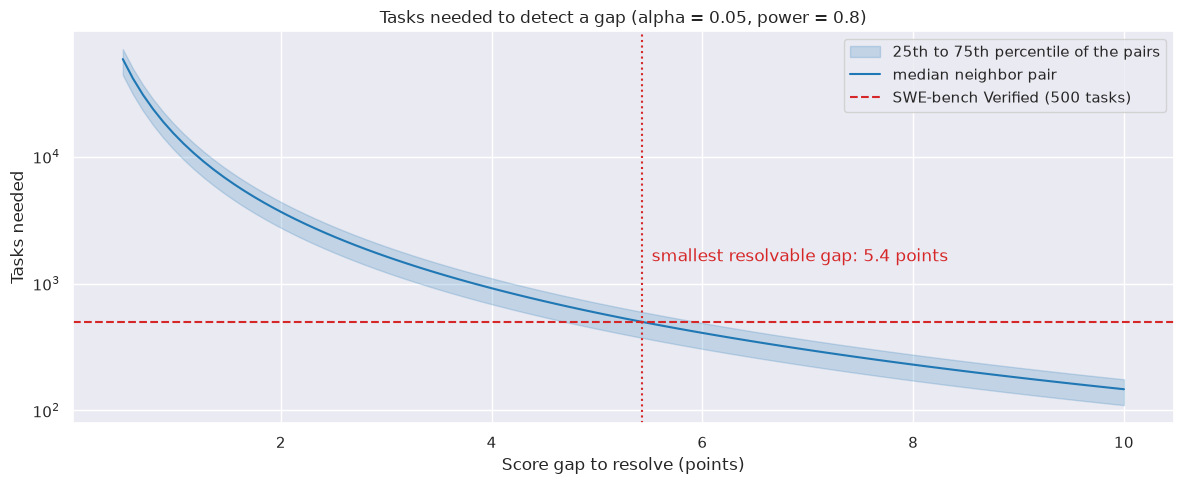

In [16]:
# Plot the tasks needed against the gap size.
utils.plot_min_tasks_curve(adjacent["sd_diff"], figsize=(12, 5))

# Part 5: Takeaways and next steps

## Takeaways

- A single SWE-bench Verified score is only known to about $\pm 4$ points
  - The median 95% interval is 8.2 points wide
- The leaderboard cannot tell neighbors apart
  - The median gap between neighbors is 0.2 points
  - None of the 172 neighbor pairs differ after the Holm correction
  - Only 2 differ before it
- The top is a statistical tie
  - 18 agents, down to rank 19 at 74.4%, cannot be separated from the leader
    at 79.2%
- 500 tasks are too few for the gaps on the leaderboard
  - Resolving a 1-point gap with 80% power needs about 14,700 tasks
  - With 500 tasks, the smallest resolvable gap is about 5.4 points
- These intervals only cover the luck of which tasks are in the benchmark
  - Each submission reports 1 run per task, so run-to-run luck is not included
  - The real uncertainty is larger

## Next steps

- Milestone 2: measure run-to-run luck
  - Run small open models 5 times per task on HumanEval+ and MBPP+
  - Everything runs locally with Ollama
- Milestone 3:
  - Split-half rank correlation, to test whether rankings hold up
  - A Bayesian 2PL item response theory model in NumPyro, to estimate task
    difficulty and the effective size of the benchmark
- Milestone 4: the winner's curse of trying many scaffolds
  - 82 of the 173 submissions allow 2 or more attempts per task (Cell 1.4)
  - The same EntroPO system scores 52.2% with 1 attempt and 60.4% with several